# 04 — Fitting 7 billion parameters on one GPU: memory and 4-bit quantization

**Chapter 3** · suggested time: 25 min · CPU only (< 1 min of compute) · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_3/04_memory_and_quantization.ipynb)

![Chapter 3 roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_3/figures/00_roadmap.png)

Google Colab's free GPU (NVIDIA T4) has **15 GB** of memory. Mistral 7B in BF16 already weighs **14.5 GB** before training anything. This notebook does the math, then builds by hand the **NF4 quantization** that makes the QLoRA of notebook 05 possible.

**By the end of this notebook you will be able to:**
1. break down the memory of a training run: weights, gradients, optimizer states, activations;
2. estimate the memory of a full fine-tuning, a LoRA and a QLoRA of Mistral 7B;
3. quantize a matrix to 4 bits **block-wise**, and explain why NF4 is better than evenly spaced levels;
4. explain QLoRA, **gradient accumulation** and **gradient checkpointing**.

In [1]:
# Setup. On Colab: we fetch the course repository (data + shared modules).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("finetune.py"):
    !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_3
sys.path.insert(0, "../chapter_2")   # minigpt.py from chapter 2

import math, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless tqdm warning
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import finetune as ft   # finetune.py, next to this notebook
torch.manual_seed(1337)
print("PyTorch", torch.__version__)
import minigpt
import numpy as np
from pathlib import Path

PyTorch 2.15.0+cu132


## 1. Where does the memory go during training?

| Type | Bytes per number | Use |
|---|---|---|
| FP32 | 4 | "classic" precision (chapter 2) |
| BF16 / FP16 | 2 | weights and computations of modern LLMs |
| INT8 | 1 | 8-bit quantization |
| NF4 | 0.5 | QLoRA's 4-bit quantization |

For **each trainable parameter**, training with AdamW stores:
- the **weight** itself;
- its **gradient** (same size);
- two **AdamW states** (mean and variance of the gradients, chapter 2 notebook 02), in FP32: 8 bytes.

On top of that come the **activations**: the intermediate outputs of each layer, kept during the forward pass to compute the backward pass. They depend on the **batch** and the **sequence length**, not on the number of parameters.

For Mistral 7B (7.25 billion parameters), `ft.training_memory` does the math:

                   weights   grads   AdamW  activ.   TOTAL   (GB, batch 1 x 512 tokens)
Full FT (BF16)       13.50   13.50   54.00    0.32    81.3
LoRA (BF16 base)     13.66    0.16    0.31    0.32    14.4
QLoRA (NF4 base)      4.10    0.16    0.31    0.32     4.9


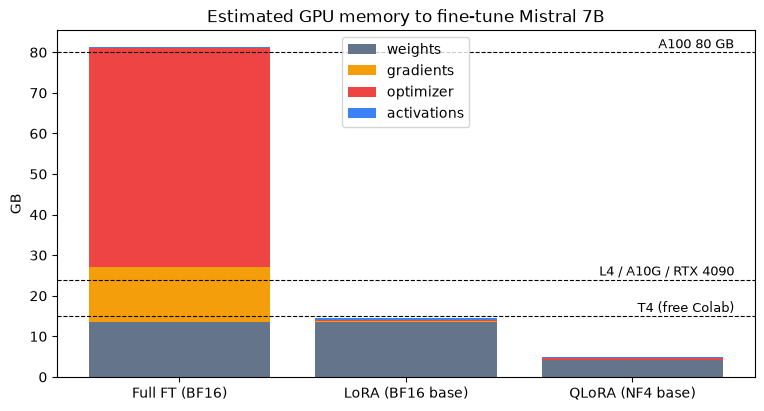

In [2]:
methods = {"full": "Full FT (BF16)", "lora": "LoRA (BF16 base)", "qlora": "QLoRA (NF4 base)"}
estimates = {m: ft.training_memory(m, r=16, batch=1, seq=512) for m in methods}

print(f"{'':18s} {'weights':>7s} {'grads':>7s} {'AdamW':>7s} {'activ.':>7s} {'TOTAL':>7s}   (GB, batch 1 x 512 tokens)")
for m, e in estimates.items():
    print(f"{methods[m]:18s} " + " ".join(f"{v:7.2f}" for v in e.values()) + f" {sum(e.values()):7.1f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
bottom = np.zeros(3)
for part, color in zip(["weights", "gradients", "optimizer", "activations"], ["#64748b", "#f59e0b", "#ef4444", "#3b82f6"]):
    values = np.array([estimates[m][part] for m in methods])
    ax.bar(list(methods.values()), values, bottom=bottom, label=part, color=color)
    bottom += values
for gpu, gb in [("T4 (free Colab)", 15), ("L4 / A10G / RTX 4090", 24), ("A100 80 GB", 80)]:
    ax.axhline(gb, ls="--", color="black", lw=0.8)
    ax.text(2.45, gb + 1, gpu, ha="right", fontsize=9)
ax.set_ylabel("GB"); ax.set_title("Estimated GPU memory to fine-tune Mistral 7B"); ax.legend(loc="upper center")
plt.show()

**How to read it:**
- **Full fine-tuning**: ~81 GB, two thirds of it for AdamW. You need an A100 80 GB, in practice several GPUs (activations and CUDA overhead add up).
- **LoRA**: gradients and AdamW almost **disappear** (42 M trainable parameters instead of 7,250 M). But the BF16 base still takes 13.5 GB: it does not fit on a T4.
- **QLoRA**: we store the base in **4 bits** → ~4 GB of weights. Total ≈ 5 GB: fits on a T4.

These figures are **orders of magnitude**: the CUDA context (~0.5–1 GB), memory fragmentation and dequantization buffers add 1 to 3 GB. In notebook 05, we measure the real memory with `torch.cuda.max_memory_allocated()`.

## 2. Activations: sequence length and gradient checkpointing

Activations are proportional to the number of tokens in the batch (`batch × seq`). Without precautions, you need to keep ~34·d bytes per token **and per layer** (Korthikanti et al., 2022).

**Gradient checkpointing** keeps only the **input** of each block during the forward pass; during the backward pass, it **recomputes** the block's forward pass to get its activations back. Memory divided by ~10, compute slowed down by about 30%.

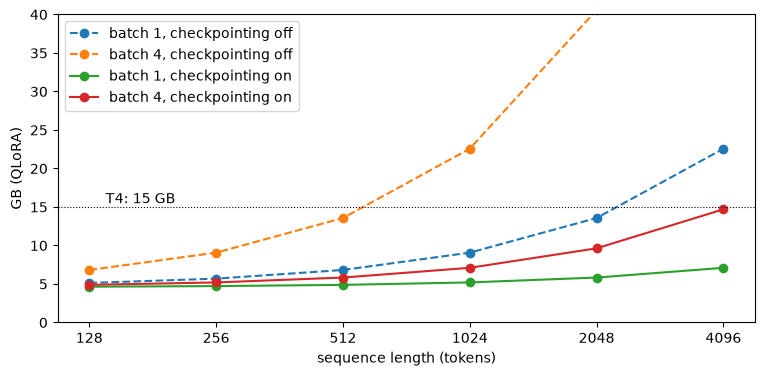

In [3]:
lengths = [128, 256, 512, 1024, 2048, 4096]
fig, ax = plt.subplots(figsize=(9, 4))
for gc, style in [(False, "o--"), (True, "o-")]:
    for batch in [1, 4]:
        tot = [sum(ft.training_memory("qlora", batch=batch, seq=s, gradient_checkpointing=gc).values()) for s in lengths]
        ax.plot(lengths, tot, style, label=f"batch {batch}, checkpointing {'on' if gc else 'off'}")
ax.axhline(15, color="black", lw=0.8, ls=":"); ax.text(140, 15.5, "T4: 15 GB")
ax.set_xscale("log", base=2); ax.set_xticks(lengths, lengths)
ax.set_xlabel("sequence length (tokens)"); ax.set_ylabel("GB (QLoRA)"); ax.set_ylim(0, 40); ax.legend()
plt.show()

This is why we chose `max_length = 512` from the data (notebook 02) and not 32,768: without checkpointing, a few thousand tokens are enough to saturate the GPU.

## 3. How many LoRA parameters?

`target_modules` and `r` set the number of trainable parameters (formula from notebook 03: `r·(d + k)` per matrix, × 32 layers).

In [4]:
attention = ["q_proj", "k_proj", "v_proj", "o_proj"]
all_linear = attention + ["gate_proj", "up_proj", "down_proj"]
n_total = sum(ft.mistral_parameters().values())
print(f"{'targets':22s} " + " ".join(f"{'r=' + str(r):>16s}" for r in [8, 16, 32, 64]))
for name, targets in [("q, v (original LoRA)", ["q_proj", "v_proj"]), ("attention (q,k,v,o)", attention), ("all linear layers", all_linear)]:
    print(f"{name:22s} " + " ".join(f"{ft.lora_parameters(r, targets) / 1e6:7.1f} M ({ft.lora_parameters(r, targets) / n_total:5.2%})" for r in [8, 16, 32, 64]))

targets                             r=8             r=16             r=32             r=64
q, v (original LoRA)       3.4 M (0.05%)     6.8 M (0.09%)    13.6 M (0.19%)    27.3 M (0.38%)
attention (q,k,v,o)        6.8 M (0.09%)    13.6 M (0.19%)    27.3 M (0.38%)    54.5 M (0.75%)
all linear layers         21.0 M (0.29%)    41.9 M (0.58%)    83.9 M (1.16%)   167.8 M (2.31%)


In notebook 05: **r = 16 on all linear layers**, that is 42 M parameters (0.58%). QLoRA (Dettmers et al., 2023) showed that adapting **all** linear layers matters more than the value of `r`.

---
## 4. Quantizing: sorting weights into 16 bins

Quantizing to 4 bits means replacing each weight by one of **16 levels** (2⁴), and storing only the **index** of the level (4 bits). The recipe:
1. cut the matrix into **blocks** of 64 weights;
2. divide each block by its **absolute maximum** (the block's *constant*, stored separately): the weights are then in [-1, 1];
3. replace each weight by the **nearest level**.

To reconstruct (dequantize): `weight ≈ level[code] × constant`.

### Why blocks? Outliers

In [5]:
torch.manual_seed(0)
w = torch.randn(4096) * 0.02          # typical weights: small, around 0
w[100] = 1.0                          # a single outlier (common in LLMs)

for block_size in [4096, 64]:
    codes, _, w_q = ft.quantize_blockwise(w, ft.INT4, block_size)
    error = (w - w_q).abs().mean().item()
    levels_used = len(set(codes.flatten().tolist()))
    print(f"block of {block_size:4d} weights: mean error {error:.5f} | levels used: {levels_used} / 16")

block of 4096 weights: mean error 0.05095 | levels used: 3 / 16
block of   64 weights: mean error 0.00252 | levels used: 16 / 16


With **a single constant** for the whole matrix, the outlier (1.0) sets the scale: the 16 levels are 0.13 apart and **all** the ordinary weights (around 0.02) fall into the two bins around zero: 4 bits wasted to keep only a sign. The error is 20 times larger. With **blocks of 64**, only the outlier's block is damaged.

### Why NF4? Weights follow a normal distribution

With 16 **evenly spaced** levels (`INT4`), we waste bins: a network's weights are concentrated near 0, the extreme bins are almost empty. **NF4** (*4-bit NormalFloat*) places the 16 levels at the **quantiles** of a normal distribution: each bin gets roughly **the same number of weights**.

normalized quantiles: ['-1.00', '-0.70', '-0.54', '-0.41', '-0.31', '-0.21', '-0.13', '-0.04', '+0.04', '+0.13', '+0.21', '+0.31', '+0.41', '+0.54', '+0.70', '+1.00']
NF4 (bitsandbytes)  : ['-1.00', '-0.70', '-0.53', '-0.39', '-0.28', '-0.18', '-0.09', '+0.00', '+0.08', '+0.16', '+0.25', '+0.34', '+0.44', '+0.56', '+0.72', '+1.00']


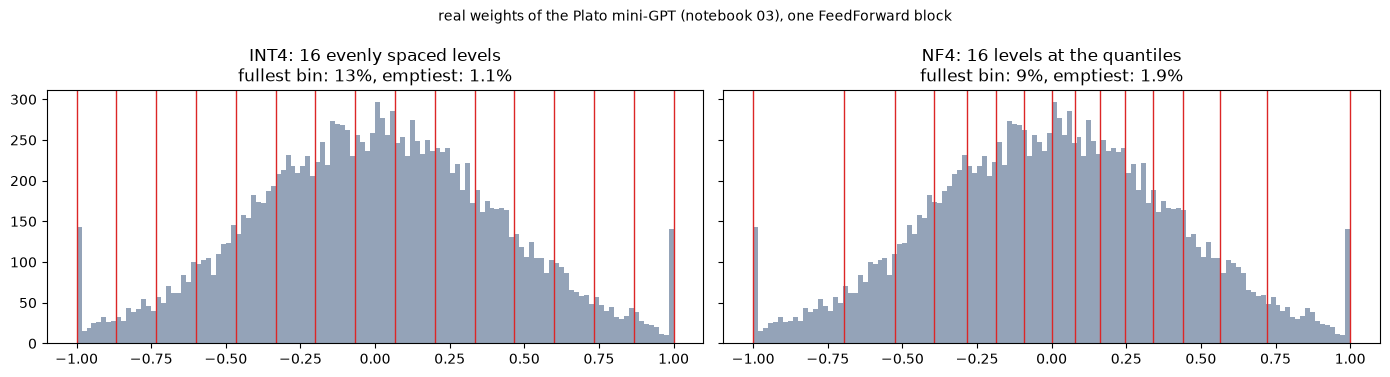

In [6]:
from torch.distributions import Normal
# Approximate reconstruction of NF4: quantiles of the normal distribution, renormalized to [-1, 1]
# (QLoRA's exact version is asymmetric so as to have an exact zero)
q = Normal(0, 1).icdf(torch.linspace(0.03, 0.97, 16))
print("normalized quantiles:", [f"{v:+.2f}" for v in (q / q.abs().max()).tolist()])
print("NF4 (bitsandbytes)  :", [f"{v:+.2f}" for v in ft.NF4.tolist()])

ckpt = Path("checkpoints/minigpt_plato.pt")
if ckpt.exists():
    weights = torch.load(ckpt)["state_dict"]["blocks.1.ffwd.net.0.weight"].flatten()
    source = "real weights of the Plato mini-GPT (notebook 03), one FeedForward block"
else:
    weights = torch.randn(16384) * 0.05
    source = "Gaussian weights (run notebook 03 to use real weights)"
blocks = weights[: len(weights) // 64 * 64].reshape(-1, 64)
normalized = (blocks / blocks.abs().amax(1, keepdim=True)).flatten()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, (name, levels) in zip(axes, [("INT4: 16 evenly spaced levels", ft.INT4), ("NF4: 16 levels at the quantiles", ft.NF4)]):
    ax.hist(normalized, bins=120, color="#94a3b8")
    for v in levels:
        ax.axvline(v, color="#dc2626", lw=1)
    codes = (normalized.unsqueeze(-1) - levels).abs().argmin(-1)
    fill = torch.bincount(codes, minlength=16).float() / len(codes)
    ax.set_title(f"{name}\nfullest bin: {fill.max():.0%}, emptiest: {fill.min():.1%}")
fig.suptitle(source, fontsize=10)
plt.tight_layout(); plt.show()

In [7]:
torch.manual_seed(0)
W = torch.randn(1024, 1024) * 0.02
for name, levels in [("INT4", ft.INT4), ("NF4", ft.NF4)]:
    _, _, W_q = ft.quantize_blockwise(W, levels, block_size=64)
    print(f"{name}: mean squared error {((W - W_q) ** 2).mean().item():.3e}")

INT4: mean squared error 4.037e-06


NF4: mean squared error 3.383e-06


NF4 reduces the quantization error for the same number of bits. What matters in the end is the effect on the **model**: let's quantize all the linear layers of the Plato mini-GPT (notebook 03) and measure its loss.

In [8]:
if not ckpt.exists():
    print("Run notebook 03 first (it creates checkpoints/minigpt_plato.pt).")
else:
    saved = torch.load(ckpt)
    chars = saved["chars"]; stoi = {c: i for i, c in enumerate(chars)}
    text = ft.load_text("plato")
    data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
    p_train, p_val = data[: int(0.9 * len(data))], data[int(0.9 * len(data)):]

    def quantized_loss(levels):
        m = minigpt.GPTLanguageModel(len(chars), 64, 64, 4, 4, dropout=0.0)
        m.load_state_dict(saved["state_dict"])
        if levels is not None:
            with torch.no_grad():
                for name, module in m.named_modules():
                    if isinstance(module, nn.Linear) and name.startswith("blocks"):
                        module.weight.copy_(ft.quantize_blockwise(module.weight, levels, 64)[2])
        torch.manual_seed(0)
        return minigpt.estimate_loss(m, p_train, p_val, 32, 64, eval_iters=50)["val"]

    for name, levels in [("FP32 (reference)", None), ("INT4, blocks of 64", ft.INT4), ("NF4, blocks of 64", ft.NF4)]:
        print(f"{name:22s} Plato val = {quantized_loss(levels):.4f}")

FP32 (reference)       Plato val = 1.4497


INT4, blocks of 64     Plato val = 1.4632


NF4, blocks of 64      Plato val = 1.4620


The weights go from 32 to 4 bits (÷ 8) and the loss barely moves. On a 7-billion-parameter model, which is highly redundant, the effect is even smaller: the QLoRA paper shows that an NF4 fine-tuning reaches the quality of a 16-bit fine-tuning.

### The cost of the constants, and double quantization

Each block of 64 weights has an FP32 constant (32 bits): **0.5 bit** more per weight, that is 450 MB on Mistral 7B. QLoRA **also quantizes the constants** (to 8 bits, in blocks of 256):

In [9]:
n_quantized = ft.mistral_parameters()["blocks (linear)"]
single = 32 / 64
double = 8 / 64 + 32 / (64 * 256)
for name, bits in [("NF4 alone", single), ("NF4 + double quantization", double)]:
    print(f"{name:28s}: {4 + bits:.3f} bits per weight -> {n_quantized * (4 + bits) / 8 / 1024**3:.2f} GB for the linear layers")

NF4 alone                   : 4.500 bits per weight -> 3.66 GB for the linear layers
NF4 + double quantization   : 4.127 bits per weight -> 3.35 GB for the linear layers


---
## 5. QLoRA: putting it all together

![QLoRA](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_3/figures/04_qlora.png)

- The base is **stored** in NF4 and **frozen**.
- During computation, each layer is **dequantized** on the fly to BF16 (or FP16 on a T4, which does not support BF16), multiplied, then thrown away.
- The LoRA adapters stay in high precision and are the **only** ones to receive gradients.
- The gradient **flows through** the frozen base (otherwise the adapters of the first layers would receive nothing), but no gradient is **stored** for its weights.

In notebook 05, all of this fits in one configuration:

```python
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",              # the 16 levels of ft.NF4
    bnb_4bit_use_double_quant=True,         # constants quantized to 8 bits
    bnb_4bit_compute_dtype=torch.bfloat16,  # dequantization to BF16 (FP16 on T4)
)
```

---
## 6. Two training tricks

### Gradient accumulation

We would like a batch of 16 examples, but only 4 fit in memory. Solution: do 4 forward/backward passes of 4 examples **without** calling `optimizer.step()`, dividing each loss by 4. The gradients **add up** in `.grad` (that is why we call `zero_grad()` in chapter 2!). Let's check that it is **exactly** the same gradient:

In [10]:
torch.manual_seed(0)
m = minigpt.GPTLanguageModel(vocab_size=50, block_size=16, n_embd=32, n_head=4, n_layer=2, dropout=0.0)
xb = torch.randint(0, 50, (16, 16)); yb = torch.randint(0, 50, (16, 16))

m.zero_grad()
_, loss = m(xb, yb); loss.backward()                       # one batch of 16
g_batch = m.lm_head.weight.grad.clone()

m.zero_grad()
for i in range(4):                                         # 4 micro-batches of 4
    _, loss = m(xb[4 * i: 4 * i + 4], yb[4 * i: 4 * i + 4])
    (loss / 4).backward()                                  # the gradients ACCUMULATE
g_accumulated = m.lm_head.weight.grad.clone()

print("identical gradients:", torch.allclose(g_batch, g_accumulated, atol=1e-6))

identical gradients: True


In notebook 05: `per_device_train_batch_size=4, gradient_accumulation_steps=4` → **effective batch** = 4 × 4 × (number of GPUs = 1) = **16**.

> With sequences of different lengths, the equality is no longer exact (the mean is taken per token); recent libraries correct this.

### Gradient checkpointing

Seen in §2: we trade **compute** for **memory**. In `SFTConfig`, it is `gradient_checkpointing=True` (enabled by default in TRL).

### "Paged" optimizers

Memory spikes (an unusually long sequence) can crash a training run that has been going for hours. `optim="paged_adamw_8bit"` stores the AdamW states in 8 bits and can **temporarily move them to CPU RAM** during a spike, instead of raising `CUDA out of memory`.

---
## 7. Which GPU on Colab?

| GPU | Memory | BF16 | Availability | Mistral 7B QLoRA |
|---|---|---|---|---|
| **T4** | 15 GB | no (FP16) | free (variable quotas) | ✔ batch 4 × 512 tokens |
| **L4** | 24 GB | yes | Colab Pro | ✔ faster |
| **A100** | 40 GB | yes | Colab Pro | ✔ very comfortable; BF16 LoRA possible |

Notebook 05 detects the GPU and picks FP16 or BF16 automatically.

## Summary

- Training memory = **weights + gradients + optimizer states + activations**. AdamW costs 8 bytes per trainable parameter.
- **LoRA** removes the base's gradients and AdamW states; **QLoRA** also stores the base in **NF4** (4 bits): Mistral 7B goes from ~81 GB (full FT) to ~5 GB.
- **Block-wise** quantization (against outliers) with levels at the **quantiles of the normal distribution** (NF4).
- **Gradient accumulation**: a large effective batch with little memory, identical result.
- **Gradient checkpointing**: recompute the activations instead of storing them.

**Check your understanding**
1. Why do AdamW's states weigh 4 times more than the BF16 weights?
2. How many GB does Mistral 7B weigh in INT8? Would it fit on a T4 for a LoRA?
3. Why must the base stay **frozen** in QLoRA?
4. You get `CUDA out of memory`. In which order do you try: reducing `max_length`, reducing the batch and increasing accumulation, enabling checkpointing, reducing the LoRA modules?